# 02. Làm sạch Dữ liệu & Nội suy Chuỗi Thời gian

> Kiểm toán bản chất các giá trị bằng `0.0` và xây dựng quy trình phục hồi dữ liệu cảm biến trên cơ sở thực nghiệm cho hai bộ dữ liệu `PEMS08` (tập nghiên cứu chính) và `PEMS04` (tập xác thực độc lập).

### Tóm tắt
* **Bối cảnh:** Từ kết quả kiểm toán dữ liệu thô ở [01. Tổng quan Dự án & Lựa chọn Tập dữ liệu (`01_Overview.ipynb`)](./01_Overview.ipynb), cả `PEMS08` và `PEMS04` đều xuất hiện các giá trị bằng `0.0` ở kênh `Lưu lượng` và `Độ chiếm dụng` trong khi `Vận tốc` không có giá trị `0.0`.
* **Hai câu hỏi dẫn dắt của bước này:**
  1. Làm thế nào để tách bạch khách quan giữa trạng thái đường vắng ban đêm hợp lệ và lỗi mất tín hiệu cảm biến?
  2. Khi đã khoanh vùng được các đoạn lỗi ngắn và dài, phương pháp nội suy nào phục hồi chính xác mà vẫn bảo toàn đặc trưng dao động và phân phối gốc?
* **Kết quả đầu ra:** Hai bộ dữ liệu sạch lưu tại `outputs/cleaned/PEMS08_clean.npz` và `outputs/cleaned/PEMS04_clean.npz` cùng hệ thống biểu đồ kiểm chứng.

---
## 1. Thiết lập môi trường & Nạp dữ liệu gốc

Dữ liệu đầu vào gồm mảng chuỗi thời gian `(T, N, 3)` và danh sách cạnh có hướng `(from, to, cost)` của `PEMS08` và `PEMS04`. Trong cả hai tập, biến `Vận tốc` có giá trị cực tiểu là `3.0 mph` (không ghi nhận giá trị `0.0`), do đó quá trình kiểm toán và nội suy tập trung vào hai biến `Lưu lượng` và `Độ chiếm dụng`.

In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge

ROOT = Path("..").resolve()
DATA_DIR, CLEAN_DIR, FIG_DIR = ROOT / "datasets" / "data", ROOT / "outputs" / "cleaned", ROOT / "outputs" / "figures"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 300})
SEED = 42
np.random.seed(SEED)

raw = {}
for n in ["PEMS08", "PEMS04"]:
    arr = np.load(DATA_DIR / n / f"{n}.npz")["data"].astype(np.float32)
    edges = pd.read_csv(DATA_DIR / n / f"{n}.csv")
    edges.columns = edges.columns.str.strip().str.lower()
    raw[n] = {"tensor": arr, "edges": edges}
    print(f"{n}: shape={arr.shape}, edges={len(edges)}, speed==0: {(arr[:,:,2]<=0).sum()}")

PEMS08: shape=(17856, 170, 3), edges=295, speed==0: 0
PEMS04: shape=(16992, 307, 3), edges=340, speed==0: 0


---
## 2. Cơ sở thực nghiệm phân biệt trạng thái đường vắng và lỗi cảm biến

Giá trị `0.0` ở kênh lưu lượng và độ chiếm dụng không đồng nghĩa tuyệt đối với hư hỏng thiết bị, vì vào khung giờ thấp điểm ban đêm có thể tồn tại các khoảng thời gian 5 phút không có phương tiện đi qua.

Để thiết lập ngưỡng phân loại khách quan, ta thực hiện hai bước đo riêng biệt trên `PEMS08`:
1. **Trên nhóm trạm không có giá trị `<= 0` trong suốt 62 ngày (`120/170` trạm):** Tính phân vị cực trị dưới `1%` (`P1`) của lưu lượng trong khung giờ ban ngày (`06:00–22:00`) và ban đêm (`22:00–06:00`) để biết mức lưu lượng thấp nhất thông thường.
2. **Trên nhóm trạm có xuất hiện `0.0` (`50/170` trạm còn lại):** Lọc riêng các chuỗi `= 0` xảy ra hoàn toàn vào ban đêm có lưu lượng bước liền kề `≤ P1` ban đêm, rồi tính phân vị `95%` (`P95`) độ dài của chúng.

In [34]:
p8 = raw["PEMS08"]["tensor"]
f8 = p8[:, :, 0]
clean_mask_8 = (f8 > 0).all(axis=0) & (p8[:, :, 1] > 0).all(axis=0)
clean_flows = f8[:, clean_mask_8]

hrs = (np.arange(p8.shape[0]) % 288) / 12.0
is_day_t = (hrs >= 6.0) & (hrs <= 22.0)
p1_day, p1_night = float(np.percentile(clean_flows[is_day_t], 1)), float(np.percentile(clean_flows[~is_day_t], 1))

night_low_lens = []
for n in range(p8.shape[1]):
    t = 0
    while t < p8.shape[0]:
        if f8[t, n] <= 0 or p8[t, n, 1] <= 0:
            t1 = t
            while t1 < p8.shape[0] and (f8[t1, n] <= 0 or p8[t1, n, 1] <= 0): t1 += 1
            nb = max(float(f8[t-1, n]) if t > 0 else 0.0, float(f8[t1, n]) if t1 < p8.shape[0] else 0.0)
            if (not is_day_t[t:t1].any()) and nb <= p1_night:
                night_low_lens.append(t1 - t)
            t = t1
        else:
            t += 1
dur_th = int(np.percentile(night_low_lens, 95))
print(f"Trạm sạch: {clean_mask_8.sum()}/{p8.shape[1]} | P1_day={p1_day:.1f}, P1_night={p1_night:.1f}, P95_dur={dur_th} bước ({dur_th*5} phút)")

Trạm sạch: 120/170 | P1_day=69.0, P1_night=16.0, P95_dur=6 bước (30 phút)


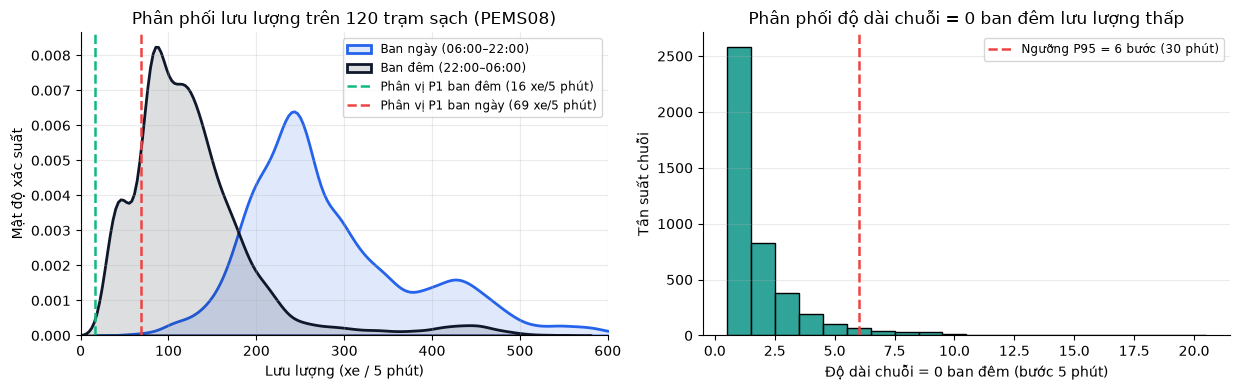

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.0))
sns.kdeplot(clean_flows[is_day_t].ravel()[::30], ax=axes[0], color="#2563eb", lw=2, fill=True, alpha=0.14, label="Ban ngày (06:00–22:00)")
sns.kdeplot(clean_flows[~is_day_t].ravel()[::30], ax=axes[0], color="#0f172a", lw=2, fill=True, alpha=0.14, label="Ban đêm (22:00–06:00)")
axes[0].axvline(p1_night, color="#10b981", ls="--", lw=1.8, label=f"Phân vị P1 ban đêm ({p1_night:.0f} xe/5 phút)")
axes[0].axvline(p1_day, color="#ef4444", ls="--", lw=1.8, label=f"Phân vị P1 ban ngày ({p1_day:.0f} xe/5 phút)")
axes[0].set(xlim=(0, 600), xlabel="Lưu lượng (xe / 5 phút)", ylabel="Mật độ xác suất",
            title=f"Phân phối lưu lượng trên {clean_mask_8.sum()} trạm sạch (PEMS08)")
axes[0].legend(frameon=True, fontsize=8.5); axes[0].grid(alpha=0.25)

sns.histplot(np.clip(night_low_lens, 1, 20), bins=range(1, 22), discrete=True, ax=axes[1], color="#0d9488", alpha=0.85)
axes[1].axvline(dur_th, color="#ef4444", ls="--", lw=1.8, label=f"Ngưỡng P95 = {dur_th} bước ({dur_th*5} phút)")
axes[1].set(xlabel="Độ dài chuỗi = 0 ban đêm (bước 5 phút)", ylabel="Tần suất chuỗi",
            title="Phân phối độ dài chuỗi = 0 ban đêm lưu lượng thấp")
axes[1].legend(frameon=True, fontsize=8.5); axes[1].grid(axis="y", alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "nb02_empirical_thresholds.png", bbox_inches="tight")
plt.show()

> **Nhận xét:**
>
> * **Ngưỡng lưu lượng nền (từ `120/170` trạm không có giá trị `<= 0` trong suốt 62 ngày):** `99%` quan sát ban ngày đạt lưu lượng ≥ **`69.0` xe/5 phút** và ban đêm đạt ≥ **`16.0` xe/5 phút**.
> * **Ngưỡng độ dài chuỗi vắng đêm (từ `50/170` trạm còn lại có xuất hiện `0.0`):** `95%` các chuỗi `0.0` thuần ban đêm có lưu lượng liền kề thấp (`≤ 16.0` xe/5 phút) chỉ kéo dài tối đa **`6` bước (30 phút)**.
>
> Dựa trên hai đặc trưng phân phối này, một chuỗi `<= 0` được phân loại là **lỗi mất tín hiệu** nếu thỏa mãn ít nhất một trong bốn điều kiện:
> 1. Kéo dài vượt `6` bước;
> 2. Mất đồng bộ giữa hai kênh `Lưu lượng` và `Độ chiếm dụng`;
> 3. Xuất hiện trong khung giờ ban ngày với lưu lượng liền kề ≥ `16.0`;
> 4. Suy giảm đột ngột về `0` từ mức lưu lượng liền kề ≥ `69.0`.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Áp dụng bộ 4 tiêu chí này lên toàn bộ `PEMS08` và `PEMS04` thì thực tế có bao nhiêu phần trăm điểm `0.0` là lỗi cảm biến thật sự, và các đoạn mất tín hiệu kéo dài tối đa bao lâu?

---
## 3. Kiểm toán và phân loại các điểm dữ liệu bằng `0.0`

Áp dụng bộ tiêu chí thực nghiệm vừa xây dựng lên toàn bộ `PEMS08` và `PEMS04` để định lượng tỷ trọng đường vắng hợp lệ (được bảo toàn) so với lỗi mất tín hiệu cảm biến (cần nội suy).

In [36]:
def classify_zero_anomalies(arr: np.ndarray, p1_night: float, p1_day: float, dur_th: int):
    T, N, _ = arr.shape
    f, o = arr[:, :, 0], arr[:, :, 1]
    any0 = (f <= 0) | (o <= 0)
    dropout, empty_road = np.zeros((T, N), dtype=bool), np.zeros((T, N), dtype=bool)
    is_day_arr = ((np.arange(T) % 288) / 12.0 >= 6.0) & ((np.arange(T) % 288) / 12.0 <= 22.0)
    streaks = []
    for n in range(N):
        t = 0
        while t < T:
            if any0[t, n]:
                t1 = t
                while t1 < T and any0[t1, n]: t1 += 1
                L = t1 - t
                max_nb = max(float(f[t-1, n]) if t > 0 else 0.0, float(f[t1, n]) if t1 < T else 0.0)
                mismatch = bool(((f[t:t1, n] <= 0) != (o[t:t1, n] <= 0)).any())
                is_drop = (L > dur_th) or mismatch or (bool(is_day_arr[t:t1].any()) and max_nb >= p1_night) or (max_nb >= p1_day)
                (dropout if is_drop else empty_road)[t:t1, n] = True
                streaks.append({"node": n, "len": L, "is_drop": is_drop})
                t = t1
            else:
                t += 1
    return dropout, empty_road, pd.DataFrame(streaks)

audit, summary_rows = {}, []
for name in ["PEMS08", "PEMS04"]:
    arr = raw[name]["tensor"]
    drop, empty, st_df = classify_zero_anomalies(arr, p1_night, p1_day, dur_th)
    audit[name] = {"dropout": drop, "empty": empty, "streaks": st_df}
    tot0 = int((drop | empty).sum())
    summary_rows.append({
        "Bộ dữ liệu": name, "Tổng <= 0": tot0,
        "Đường vắng (giữ)": f"{int(empty.sum()):,} ({100*empty.sum()/tot0:.1f}%)",
        "Lỗi cảm biến (sửa)": f"{int(drop.sum()):,} ({100*drop.sum()/tot0:.1f}%)",
        "Số trạm lỗi": f"{(drop.sum(axis=0)>0).sum()}/{arr.shape[1]}",
        "Độ dài tối đa (bước)": int(st_df.loc[st_df["is_drop"], "len"].max()),
    })
pd.DataFrame(summary_rows)

,Bộ dữ liệu,Tổng <= 0,Đường vắng (giữ),Lỗi cảm biến (sửa),Số trạm lỗi,Độ dài tối đa (bước)
0,PEMS08,10560,"7,583 (71.8%)","2,977 (28.2%)",39/170,400
1,PEMS04,83065,"28,120 (33.9%)","54,945 (66.1%)",157/307,408


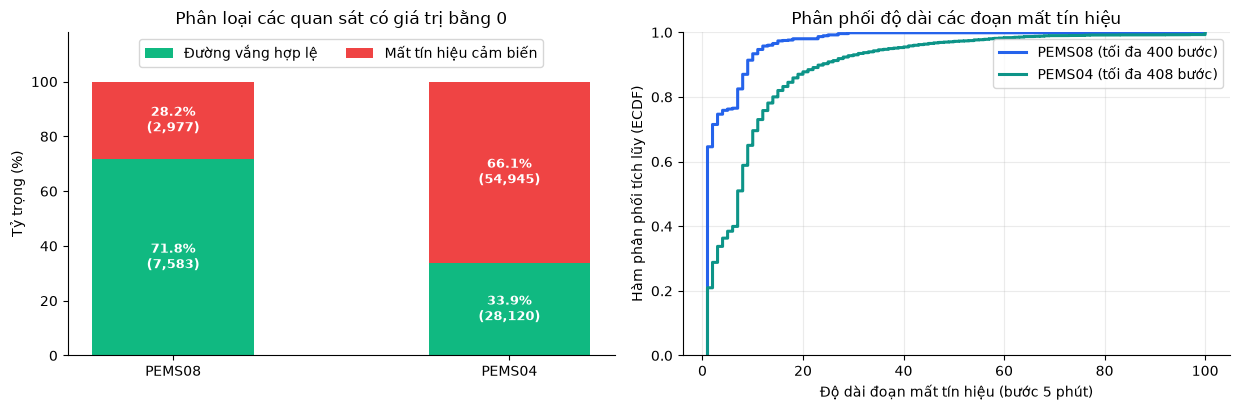

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
names = ["PEMS08", "PEMS04"]
ec, dc = [audit[n]["empty"].sum() for n in names], [audit[n]["dropout"].sum() for n in names]
tc = [e + d for e, d in zip(ec, dc)]

axes[0].bar(names, [100*e/t for e, t in zip(ec, tc)], color="#10b981", width=0.48, label="Đường vắng hợp lệ")
axes[0].bar(names, [100*d/t for d, t in zip(dc, tc)], bottom=[100*e/t for e, t in zip(ec, tc)], color="#ef4444", width=0.48, label="Mất tín hiệu cảm biến")
for i, (e, d, t) in enumerate(zip(ec, dc, tc)):
    axes[0].text(i, 50*e/t, f"{100*e/t:.1f}%\n({e:,})", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    axes[0].text(i, 100*e/t + 50*d/t, f"{100*d/t:.1f}%\n({d:,})", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
axes[0].set(ylabel="Tỷ trọng (%)", ylim=(0, 118), title="Phân loại các quan sát có giá trị bằng 0")
axes[0].legend(frameon=True, loc="upper center", ncol=2)

for n, c in [("PEMS08", "#2563eb"), ("PEMS04", "#0d9488")]:
    lens = audit[n]["streaks"].query("is_drop")["len"]
    sns.ecdfplot(np.clip(lens, 1, 100), ax=axes[1], color=c, lw=2.2, label=f"{n} (tối đa {lens.max()} bước)")
axes[1].set(xlabel="Độ dài đoạn mất tín hiệu (bước 5 phút)", ylabel="Hàm phân phối tích lũy (ECDF)",
            title="Phân phối độ dài các đoạn mất tín hiệu")
axes[1].legend(frameon=True); axes[1].grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "nb02_anomaly_audit.png", bbox_inches="tight")
plt.show()

> **Nhận xét:**
>
> * **Trên `PEMS08`:** Phần lớn các điểm `0.0` (**71.8%**, tương ứng `7.583` quan sát) thuộc trạng thái đường vắng ban đêm hợp lệ; chỉ **28.2%** (`2.977` quan sát trên `39/170` trạm) là lỗi mất tín hiệu.
> * **Trên `PEMS04`:** Ngược lại, có tới **66.1%** (`54.945` quan sát trên `157/307` trạm) là lỗi mất tín hiệu.
> * **Độ dài đoạn lỗi:** Cả hai bộ dữ liệu đều ghi nhận các đoạn đứt quãng kéo dài tới **400–408 bước (hơn 33 giờ)**.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Với những đoạn mất tín hiệu kéo dài tới hơn 33 giờ như vậy, nội suy tuyến tính đơn thuần hay trung bình chu kỳ ngày liệu có đủ chính xác, hay sẽ làm mất nhịp dao động thực của dòng xe? Ta cần thử nghiệm có kiểm soát ở Mục 4.

---
## 4. Đánh giá phương pháp phục hồi, dự đoán phần dư & xác định điểm đảo chiều `L*`

### 4.1. Khắc phục hiện tượng mất dao động trên đoạn mất dài (6 giờ = 72 bước)

Nội suy theo hồ sơ chu kỳ ngày (`Daily Profile` — tính trung vị tại cùng khung giờ `t % 288`) giúp khôi phục xu hướng cao điểm sáng–chiều nhưng làm triệt tiêu các dao động ngẫu nhiên từng 5 phút.

Để đánh giá khả năng dự đoán phần dư dao động bổ sung vào hồ sơ chu kỳ, nghiên cứu thử nghiệm che khuất có kiểm soát (`72` bước) trên `20` trạm sạch của `PEMS08` đối với bốn chiến lược:
1. **`Daily Profile`:** Chỉ dùng trung vị theo khung giờ trong ngày.
2. **`Profile + AR(1) Noise`:** Bổ sung nhiễu ngẫu nhiên có phương sai thay đổi theo giờ và tự tương quan bậc 1.
3. **`Profile + Spatial Mean`:** Hồi quy độ lệch trung bình từ các trạm lân cận trên đồ thị.
4. **`Profile + Spatial Ridge`:** Hồi quy đa biến `Ridge` trên từng trạm lân cận.

Kết quả được đo đồng thời về sai số (`MAE`, `RMSE`, `r`) lẫn mức độ bảo toàn độ biến thiên từng bước (`Step-diff Std`).

In [38]:
def get_profile(s: np.ndarray, valid_mask: np.ndarray):
    T = len(s)
    slots, x_all = np.arange(T) % 288, np.arange(T)
    lin = np.interp(x_all, x_all[valid_mask], s[valid_mask]) if valid_mask.any() else np.zeros(T, dtype=np.float32)
    pmap = pd.Series(s[valid_mask]).groupby(slots[valid_mask]).median() if valid_mask.any() else pd.Series(dtype=float)
    prof = np.where(np.isnan(p := pd.Series(slots).map(pmap).to_numpy(dtype=np.float32)), lin, p)
    return prof, lin

def spatial_mean_pred(s: np.ndarray, prof: np.ndarray, good: np.ndarray, nbs: list, f_mat: np.ndarray):
    if not nbs:
        return prof.copy(), None
    X_nb = np.column_stack([f_mat[:, u] - get_profile(f_mat[:, u], good)[0] for u in nbs])
    nb_m = X_nb.mean(axis=1)
    slope = float(np.cov((s - prof)[good], nb_m[good])[0, 1] / max(np.var(nb_m[good]), 1e-6))
    return np.maximum(prof + slope * nb_m, 0.0), X_nb

edges8, T8 = raw["PEMS08"]["edges"], p8.shape[0]
slots8, clean_20 = np.arange(T8) % 288, np.where(clean_mask_8)[0][:20]
nb_map8 = {nid: [u for u in sorted((set(edges8.loc[edges8["to"]==nid, "from"]) | set(edges8.loc[edges8["from"]==nid, "to"])) - {nid}) if clean_mask_8[u]] for nid in clean_20}
rng = np.random.default_rng(SEED)

m72 = np.zeros((T8, 20), dtype=bool)
for idx, t0 in enumerate(range(1000, 15000, 1000)): m72[t0:t0+72, idx % 20] = True

eval_d = {k: {"v": [], "d": []} for k in ["Ground Truth", "Daily Profile", "Profile + AR(1) Noise", "Profile + Spatial Mean", "Profile + Spatial Ridge"]}
for j, nid in enumerate(clean_20):
    s, bad = f8[:, nid], m72[:, j]
    good = ~bad
    prof, _ = get_profile(s, good)
    res = s - prof
    sig = pd.Series(slots8).map(pd.Series(res[good]).groupby(slots8[good]).std().fillna(res[good].std())).to_numpy(dtype=np.float32)
    z, vp = res / np.maximum(sig, 1.0), good[1:] & good[:-1]
    rho = float(np.clip(np.corrcoef(z[:-1][vp], z[1:][vp])[0, 1], 0.0, 0.95))
    s_ar = prof.copy()
    for t0 in range(1000, 15000, 1000):
        if m72[t0, j]:
            cz = (s[t0-1] - prof[t0-1]) / max(sig[t0-1], 1.0)
            for k in range(t0, t0+72):
                cz = rho * cz + np.sqrt(1 - rho**2) * rng.normal()
                s_ar[k] = max(prof[k] + cz * sig[k], 0.0)
    s_sm, X_nb = spatial_mean_pred(s, prof, good, nb_map8[nid], f8)
    s_sr = np.maximum(prof + Ridge(alpha=10.0).fit(X_nb[good], res[good]).predict(X_nb), 0.0) if X_nb is not None else prof.copy()
    preds = {"Ground Truth": s, "Daily Profile": prof, "Profile + AR(1) Noise": s_ar, "Profile + Spatial Mean": s_sm, "Profile + Spatial Ridge": s_sr}
    for idx, t0 in enumerate(range(1000, 15000, 1000)):
        if idx % 20 == j:
            for k, ap in preds.items(): eval_d[k]["v"].extend(ap[t0:t0+72]); eval_d[k]["d"].extend(np.diff(ap[t0:t0+72]))

tv = np.array(eval_d["Ground Truth"]["v"])
res_df = pd.DataFrame([{"Phương pháp": k, "MAE": round(float(np.abs(np.array(d["v"])-tv).mean()), 2),
                        "RMSE": round(float(np.sqrt(((np.array(d["v"])-tv)**2).mean())), 2),
                        "Tương quan (r)": round(float(np.corrcoef(d["v"], tv)[0, 1]), 4),
                        "Step-diff Std": round(float(np.array(d["d"]).std()), 2)} for k, d in eval_d.items()])
res_df

,Phương pháp,MAE,RMSE,Tương quan (r),Step-diff Std
0,Ground Truth,0.00,0.00,1.0000,32.25
1,Daily Profile,26.34,39.83,0.9606,10.29
2,Profile + AR(1) Noise,50.73,70.69,0.8890,39.02
3,Profile + Spatial Mean,23.45,33.47,0.9718,20.41
4,Profile + Spatial Ridge,25.02,35.72,0.9680,21.15


### 4.2. So sánh xuyên suốt `Linear`, `Daily Profile` và `Profile + Spatial Mean` (5–360 phút)
Sau khi xác định `Profile + Spatial Mean` là mô hình dự đoán phần dư hiệu quả nhất cho đoạn mất dài, ta tiếp tục kiểm chứng xem liệu có thể thay thế hoàn toàn `Linear` trên các đoạn mất ngắn hay không bằng cách quét độ dài đoạn mất `L` từ `1` đến `72` bước.

In [39]:
gap_lengths = [1, 2, 4, 6, 8, 12, 18, 24, 30, 36, 48, 72]
curve_rows = []
for L in gap_lengths:
    m = np.zeros((T8, 20), dtype=bool)
    for idx, t0 in enumerate(range(1000, 15000, 1000)): m[t0:t0+L, idx % 20] = True
    el, ep, esm = [], [], []
    for j, nid in enumerate(clean_20):
        s, bad = f8[:, nid], m[:, j]
        prof, lin = get_profile(s, ~bad)
        s_sm, _ = spatial_mean_pred(s, prof, ~bad, nb_map8[nid], f8)
        el.extend(lin[bad] - s[bad]); ep.extend(prof[bad] - s[bad]); esm.extend(s_sm[bad] - s[bad])
    curve_rows.append({"L (bước)": L, "Phút": L*5, "Linear MAE": round(float(np.abs(el).mean()), 2),
                       "Profile MAE": round(float(np.abs(ep).mean()), 2), "Profile+SpatMean MAE": round(float(np.abs(esm).mean()), 2)})

curve_df = pd.DataFrame(curve_rows)
sm_wins = curve_df[curve_df["Profile+SpatMean MAE"] < curve_df["Linear MAE"]]
L_star = int(curve_df.loc[sm_wins.index[0] - 1, "L (bước)"]) if len(sm_wins) and sm_wins.index[0] > 0 else 18
print(f"Điểm đảo chiều thực nghiệm L* = {L_star} bước ({L_star*5} phút = {L_star*5/60:.1f} giờ)")
curve_df

Điểm đảo chiều thực nghiệm L* = 18 bước (90 phút = 1.5 giờ)


,L (bước),Phút,Linear MAE,Profile MAE,Profile+SpatMean MAE
0,1,5,18.61,26.14,21.62
1,2,10,16.90,26.43,24.85
2,4,20,18.80,26.11,25.83
3,6,30,20.60,26.29,25.32
4,8,40,22.13,28.11,26.36
5,12,60,24.97,28.74,26.56
6,18,90,23.73,29.02,26.41
7,24,120,25.16,28.04,24.25
8,30,150,26.93,28.32,24.92
9,36,180,29.61,27.32,24.82


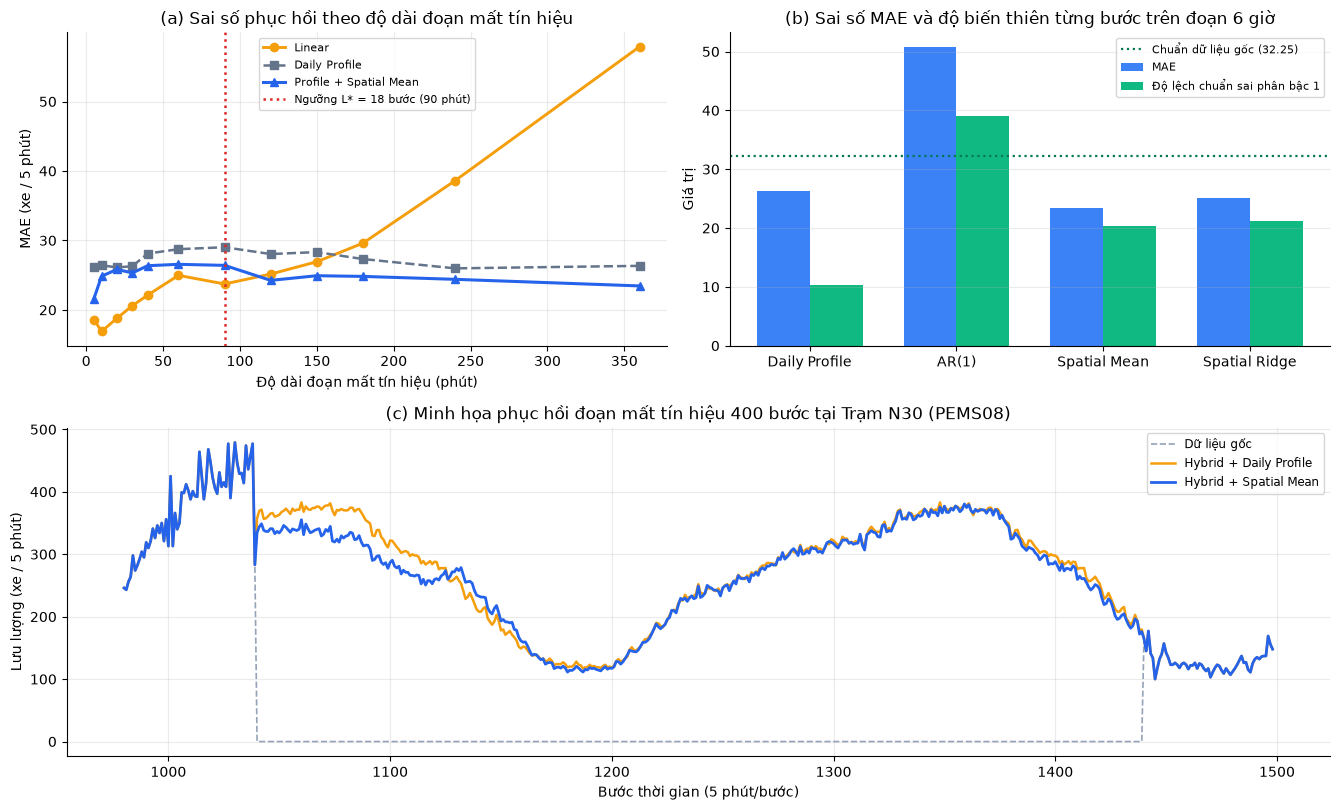

In [40]:
def apply_hybrid_cleaning(arr: np.ndarray, dropout: np.ndarray, edges: pd.DataFrame, crossover: int) -> np.ndarray:
    out = arr.copy()
    T, N, _ = out.shape
    for f in [0, 1]:
        valid_pos = (~dropout) & (out[:, :, f] > 0)
        profs = np.column_stack([get_profile(out[:, n, f], valid_pos[:, n])[0] for n in range(N)])
        lins = np.column_stack([get_profile(out[:, n, f], valid_pos[:, n])[1] for n in range(N)])
        res_all = np.where(dropout, 0.0, out[:, :, f] - profs)
        for n in np.where(dropout.any(axis=0))[0]:
            nbs = [u for u in sorted((set(edges.loc[edges["to"]==n, "from"]) | set(edges.loc[edges["from"]==n, "to"])) - {n}) if 0 <= u < N]
            pred_prof = profs[:, n].copy()
            if nbs:
                nb_valid = (~dropout[:, nbs]) & (out[:, nbs, f] > 0)
                nb_cnt = nb_valid.sum(axis=1)
                nb_mean = np.divide((res_all[:, nbs] * nb_valid).sum(axis=1), nb_cnt, out=np.zeros(T, dtype=np.float32), where=nb_cnt > 0)
                tr = valid_pos[:, n] & (nb_cnt > 0)
                if tr.sum() >= 50 and np.var(nb_mean[tr]) > 1e-8:
                    slope = float(np.cov(res_all[tr, n], nb_mean[tr])[0, 1] / np.var(nb_mean[tr]))
                    pred_prof = np.where(nb_cnt > 0, np.maximum(pred_prof + slope * nb_mean, np.maximum(0.2 * profs[:, n], 1e-4)), pred_prof)
            t = 0
            while t < T:
                if dropout[t, n]:
                    t1 = t
                    while t1 < T and dropout[t1, n]: t1 += 1
                    out[t:t1, n, f] = lins[t:t1, n] if (t1 - t) <= crossover else pred_prof[t:t1]
                    t = t1
                else: t += 1
    return out

fig = plt.figure(figsize=(13.5, 8.2))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(curve_df["Phút"], curve_df["Linear MAE"], "o-", color="#f59e0b", lw=2.1, label="Linear")
ax1.plot(curve_df["Phút"], curve_df["Profile MAE"], "s--", color="#64748b", lw=1.8, label="Daily Profile")
ax1.plot(curve_df["Phút"], curve_df["Profile+SpatMean MAE"], "^-", color="#2563eb", lw=2.2, label="Profile + Spatial Mean")
ax1.axvline(L_star * 5, color="#dc2626", ls=":", lw=1.8, label=f"Ngưỡng L* = {L_star} bước ({L_star*5} phút)")
ax1.set(xlabel="Độ dài đoạn mất tín hiệu (phút)", ylabel="MAE (xe / 5 phút)", title="(a) Sai số phục hồi theo độ dài đoạn mất tín hiệu")
ax1.legend(frameon=True, fontsize=8); ax1.grid(alpha=0.25)

ax2 = fig.add_subplot(gs[0, 1])
m_df = res_df[res_df["Phương pháp"] != "Ground Truth"]
x = np.arange(len(m_df))
ax2.bar(x - 0.18, m_df["MAE"], 0.36, color="#3b82f6", label="MAE")
ax2.bar(x + 0.18, m_df["Step-diff Std"], 0.36, color="#10b981", label="Độ lệch chuẩn sai phân bậc 1")
gt_std = float(res_df.loc[res_df["Phương pháp"]=="Ground Truth", "Step-diff Std"].iloc[0])
ax2.axhline(gt_std, color="#047857", ls=":", lw=1.6, label=f"Chuẩn dữ liệu gốc ({gt_std:.2f})")
ax2.set(xticks=x, xticklabels=["Daily Profile", "AR(1)", "Spatial Mean", "Spatial Ridge"], ylabel="Giá trị", title="(b) Sai số MAE và độ biến thiên từng bước trên đoạn 6 giờ")
ax2.legend(frameon=True, fontsize=8); ax2.grid(axis="y", alpha=0.25)

ax3 = fig.add_subplot(gs[1, :])
n_demo = int(audit["PEMS08"]["streaks"].query("is_drop").sort_values("len", ascending=False).iloc[0]["node"])
bad_idx = np.where(audit["PEMS08"]["dropout"][:, n_demo])[0]
t0, t1 = max(0, int(bad_idx[0]) - 60), min(T8, int(bad_idx[-1]) + 60)
rec_prof = apply_hybrid_cleaning(p8, audit["PEMS08"]["dropout"], edges8.iloc[:0], L_star)
rec_spat = apply_hybrid_cleaning(p8, audit["PEMS08"]["dropout"], edges8, L_star)
tx = np.arange(t0, t1)
ax3.plot(tx, p8[t0:t1, n_demo, 0], color="#94a3b8", ls="--", lw=1.2, label="Dữ liệu gốc")
ax3.plot(tx, rec_prof[t0:t1, n_demo, 0], color="#f59e0b", lw=1.8, label="Hybrid + Daily Profile")
ax3.plot(tx, rec_spat[t0:t1, n_demo, 0], color="#2563eb", lw=2.0, label="Hybrid + Spatial Mean")
ax3.set(xlabel="Bước thời gian (5 phút/bước)", ylabel="Lưu lượng (xe / 5 phút)", title=f"(c) Minh họa phục hồi đoạn mất tín hiệu 400 bước tại Trạm N{n_demo} (PEMS08)")
ax3.legend(frameon=True, fontsize=8.5); ax3.grid(alpha=0.25)

plt.tight_layout()
fig.savefig(FIG_DIR / "nb02_interpolation_and_residual_models.png", bbox_inches="tight")
plt.show()

> **Nhận xét:**
>
> 1. **Đánh giá các mô hình dự đoán độ biến thiên trên đoạn mất dài:**
>    * **`Profile + AR(1)`:** Tuy khôi phục được độ lệch chuẩn sai phân (`39.02` so với chuẩn `32.25`) nhưng làm sai số điểm tăng gần gấp đôi (`MAE` từ `26.34` lên `50.73`) do nhiễu ngẫu nhiên không phản ánh đúng xu hướng thực tại thời điểm mất tín hiệu.
>    * **`Profile + Spatial Mean`:** Khai thác phần dư đồng thời từ các trạm lân cận trên đồ thị đường bộ giúp giảm `MAE` xuống còn **`23.45`** (`RMSE = 33.47`, hệ số tương quan `r = 0.9718`), đồng thời nâng độ biến thiên từng bước từ `10.29` lên **`20.41`**.
>    * **`Spatial Ridge`:** Đạt `MAE = 25.02` (`r = 0.9680`), có cải thiện so với `Daily Profile` nhưng kém hơn nhẹ so với `Spatial Mean` do hiện tượng đa cộng tuyến giữa các nút lân cận.
>
> 2. **Vai trò của nội suy tuyến tính (`Linear`) và điểm đảo chiều `L*`:**
>    * Trong dải mất tín hiệu ngắn từ **5 đến 90 phút** (`L = 1..18`), `Linear` đạt sai số thấp nhất (`MAE = 16.90–23.73`) nhờ bám sát hai giá trị biên thực tế tại `t-1` và `t+1` của chính trạm đó.
>    * Từ mốc **120 phút (`24` bước)** trở đi, `Profile + Spatial Mean` bắt đầu vượt qua `Linear` (`24.25` so với `25.16`) và duy trì độ ổn định tới 360 phút (`23.45` so với `57.91`). Do đó, ngưỡng **`L* = 18` bước (90 phút)** được chọn làm điểm chuyển đổi tối ưu cho chiến lược kết hợp **Hybrid**.
>
> **Câu hỏi nghi vấn tiếp theo:**
>
> Khi áp dụng chiến lược Hybrid này lên toàn bộ các đoạn lỗi thực tế của `PEMS08` và `PEMS04`, dữ liệu sau làm sạch có xóa hết lỗi ẩn mà vẫn giữ nguyên phân phối thống kê gốc không?

---
## 5. Áp dụng làm sạch cuối cùng, kiểm chứng toàn vẹn & Lưu dữ liệu

Chiến lược **Hybrid (`L ≤ 18` bước dùng `Linear`; `L > 18` bước dùng `Profile + Spatial Mean`)** được áp dụng riêng lên tập mặt nạ lỗi `dropout` cho cả `PEMS08` và `PEMS04`. Bảng dưới đây đối chiếu các chỉ số thống kê trước và sau khi làm sạch.

In [41]:
verify_rows = []
for name in ["PEMS08", "PEMS04"]:
    clean_arr = apply_hybrid_cleaning(raw[name]["tensor"], audit[name]["dropout"], raw[name]["edges"], L_star)
    np.savez_compressed(CLEAN_DIR / f"{name}_clean.npz", data=clean_arr)
    for f_idx, fname in [(0, "Lưu lượng"), (1, "Độ chiếm dụng")]:
        r_v, c_v = raw[name]["tensor"][:, :, f_idx], clean_arr[:, :, f_idx]
        verify_rows.append({
            "Bộ dữ liệu": name, "Biến": fname,
            "TB Trước": round(float(r_v.mean()), 3), "TB Sau": round(float(c_v.mean()), 3),
            "Std Trước": round(float(r_v.std()), 3), "Std Sau": round(float(c_v.std()), 3),
            "Step-diff Std Sau": round(float(np.diff(c_v, axis=0).std()), 3),
            "Lỗi còn lại": int((audit[name]["dropout"] & (c_v <= 0)).sum()),
        })
pd.DataFrame(verify_rows)

,Bộ dữ liệu,Biến,TB Trước,TB Sau,Std Trước,Std Sau,Step-diff Std Sau,Lỗi còn lại
0,PEMS08,Lưu lượng,230.681,230.766,146.217,146.155,25.418,0
1,PEMS08,Độ chiếm dụng,0.065,0.065,0.046,0.046,0.012,0
2,PEMS04,Lưu lượng,211.701,212.249,158.068,157.871,33.970,0
3,PEMS04,Độ chiếm dụng,0.053,0.053,0.049,0.049,0.015,0


---
## 6. Tổng kết & Bước tiếp theo

* **Tổng hợp các tham số được xác lập từ thực nghiệm:**
  1. Bộ tiêu chí tách trạng thái đường vắng hợp lệ và lỗi cảm biến dựa trên phân vị của `120` trạm sạch thuộc `PEMS08` (`P1_day = 69.0`, `P1_night = 16.0`, phân vị `P95` độ dài chuỗi đêm `= 6` bước).
  2. Mô hình phục hồi phần dư trên đoạn mất dài **`Profile + Spatial Mean`** đạt `MAE = 23.45`, `RMSE = 33.47`, `r = 0.9718` và khôi phục độ biến thiên từng bước (`Step-diff Std = 20.41`).
  3. Điểm đảo chiều thực nghiệm **`L* = 18` bước (90 phút)** kết hợp tối ưu giữa `Linear` (đoạn ngắn) và `Profile + Spatial Mean` (đoạn dài).
* **Dữ liệu và biểu đồ đầu ra:**
  * Dữ liệu sạch: `outputs/cleaned/PEMS08_clean.npz` và `outputs/cleaned/PEMS04_clean.npz` (`0` điểm lỗi tồn đọng, bảo toàn phân phối gốc).
  * Biểu đồ: `outputs/figures/nb02_empirical_thresholds.png`, `outputs/figures/nb02_anomaly_audit.png`, `outputs/figures/nb02_interpolation_and_residual_models.png`.

### Câu hỏi nghi vấn chuyển sang Bước 03
> *Khi đã có chuỗi dữ liệu sạch không còn lỗi cảm biến, hệ thống giao thông vận hành theo nhịp điệu ngày – tuần ra sao? Ranh giới vật lý nào phân tách trạng thái thông thoáng với tắc nghẽn, ùn tắc có tập trung ở một nhóm trạm cố định hay không, và liệu có dấu hiệu tiền tắc nghẽn nào xuất hiện trước lúc kẹt xe?*

---

**Tiếp theo:** [03. Khám phá Dữ liệu Sạch (EDA) & Phân tích Tiền tắc nghẽn (`03_EDA_and_Bottleneck_Analysis.ipynb`)](./03_EDA_and_Bottleneck_Analysis.ipynb)